# ==========================================
# 📊 BI Financeiro — Macroeconomia, Taxas de Juros & Indicadores Econômicos
# EDA - Análise Exploratória de Dados (BACEN 2019-2023)
# Estudante Isaac Trenard
# ==========================================

O maior Juro Real foi de 10.27% em 06/2023


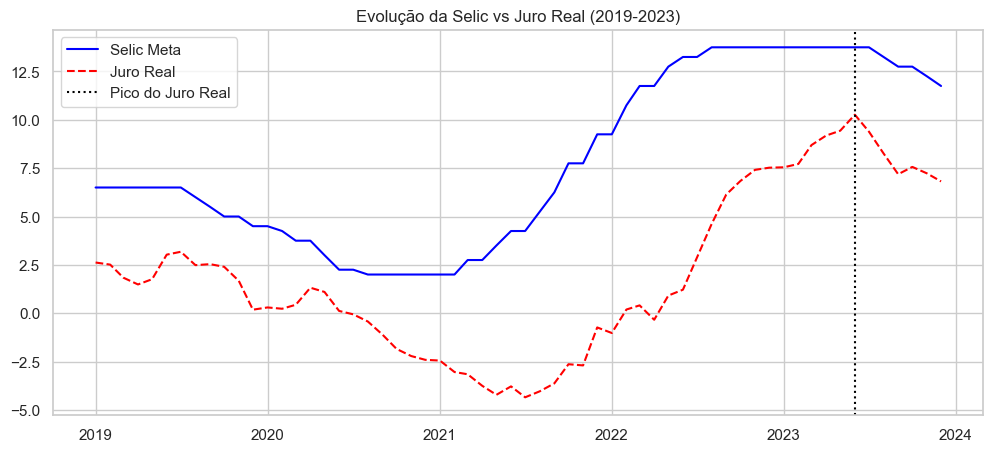

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

BASE_DIR = Path.cwd().parent
df = pd.read_csv(BASE_DIR / "data" / "processed" / "macro_consolidado.csv", parse_dates=['data'])

# 1. Identificar o momento de maior Juro Real
max_juro_real = df.loc[df['juro_real'].idxmax()]
print(f"O maior Juro Real foi de {max_juro_real['juro_real']:.2f}% em {max_juro_real['data'].strftime('%m/%Y')}")

# Gráfico
plt.figure(figsize=(12, 5))
plt.plot(df['data'], df['selic_meta'], label='Selic Meta', color='blue')
plt.plot(df['data'], df['juro_real'], label='Juro Real', color='red', linestyle='--')
plt.axvline(x=max_juro_real['data'], color='black', linestyle=':', label='Pico do Juro Real')
plt.title('Evolução da Selic vs Juro Real (2019-2023)')
plt.legend()
plt.show()

#Insight 
O gráfico evidencia o ciclo de aperto monetário. Durante a pandemia (2020-2021), o Juro Real foi negativo, o que incentivou o consumo em um momento de crise. Para conter a inflação que seguiu, o BCB elevou a Selic agressivamente, atingindo o pico de Juro Real de 10% em junho de 2023, tornando o crédito muito mais caro e desacelerando a economia. 

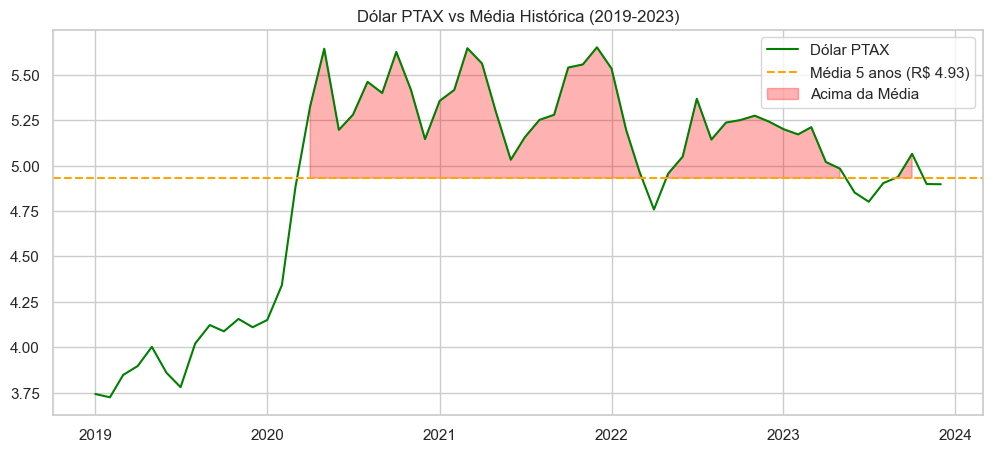

In [4]:
media_dolar = df['dolar_ptax'].mean()

plt.figure(figsize=(12, 5))
plt.plot(df['data'], df['dolar_ptax'], label='Dólar PTAX', color='green')
plt.axhline(y=media_dolar, color='orange', linestyle='--', label=f'Média 5 anos (R$ {media_dolar:.2f})')
plt.fill_between(df['data'], df['dolar_ptax'], media_dolar, where=(df['dolar_ptax'] > media_dolar), color='red', alpha=0.3, label='Acima da Média')
plt.title('Dólar PTAX vs Média Histórica (2019-2023)')
plt.legend()
plt.show()

Insight
O dólar iniciou o período cotado a R$3,75, mas sofreu um choque produto da crise glabal do COVID-19, superando os 5,50. A moeda manteve-se teimosamente acima da média de 4,93 por grande parte do tempo, reflexo do risco global e das incertezas fiscais domésticas das mudancas politicas de um governo para o outro. 

Correlação entre Dólar e IPCA (3 meses depois): 0.477


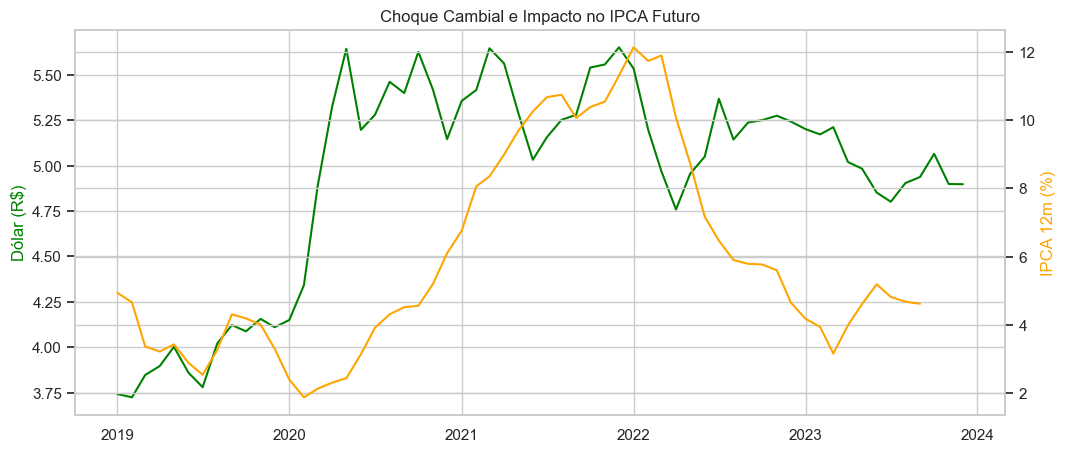

In [3]:
# Criando uma coluna com o IPCA 3 meses à frente
df['ipca_futuro_3m'] = df['ipca_12m'].shift(-3)

# Calculando correlação
correlacao_defasagem = df['dolar_ptax'].corr(df['ipca_futuro_3m'])
print(f"Correlação entre Dólar e IPCA (3 meses depois): {correlacao_defasagem:.3f}")

# Gráfico
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(df['data'], df['dolar_ptax'], color='green', label='Dólar PTAX')
ax1.set_ylabel('Dólar (R$)', color='green')
ax2 = ax1.twinx()
ax2.plot(df['data'], df['ipca_futuro_3m'], color='orange', label='IPCA 12m (3 meses depois)')
ax2.set_ylabel('IPCA 12m (%)', color='orange')
plt.title('Choque Cambial e Impacto no IPCA Futuro')
plt.show()

Insight
A correlação de 0,477 com defasagem de 3 meses comprova o efeito da 'inflação importada'. Quando o dólar sobe, produtos e insumos importados ficam mais caros. O gráfico mostra que o forte choque cambial de 2020/2021 foi um dos grandes vilões que empurraram o IPCA para cima em 2022

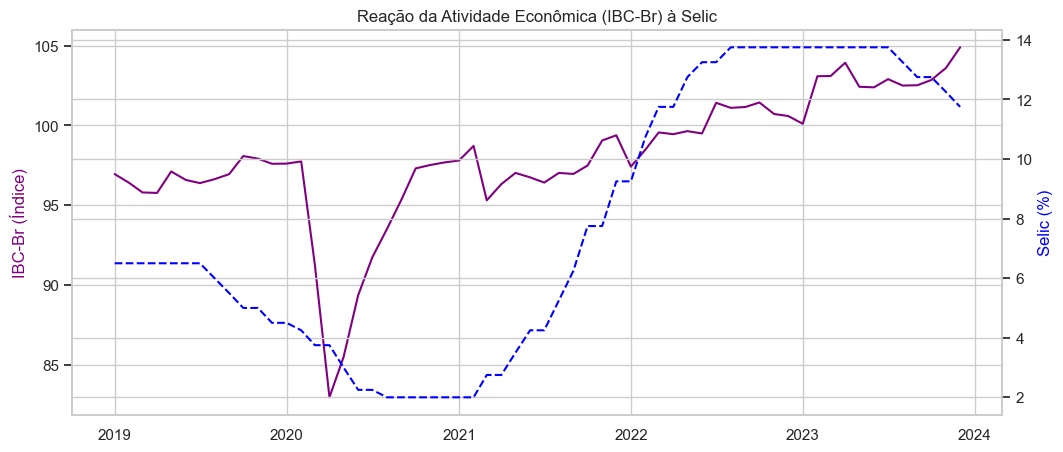

In [4]:
fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(df['data'], df['ibc_br'], color='purple', label='IBC-Br')
ax1.set_ylabel('IBC-Br (Índice)', color='purple')
ax2 = ax1.twinx()
ax2.plot(df['data'], df['selic_meta'], color='blue', linestyle='--', label='Selic Meta')
ax2.set_ylabel('Selic (%)', color='blue')
plt.title('Reação da Atividade Econômica (IBC-Br) à Selic')
plt.show()

Insight
Este gráfico ilustra o 'freio' da política monetária. A economia brasileira deu um salto de recuperação em 2021, mas, à medida que o Banco Central subiu a Selic (linha azul), o ritmo de crescimento da atividade (IBC-Br) estagnou. Juros altos esfriam a economia.

--- TOP 5 Correlações Positivas ---


juro_real   selic_meta    0.782120
selic_meta  juro_real     0.782120
ibc_br      selic_meta    0.733772
selic_meta  ibc_br        0.733772
juro_real   ibc_br        0.553459
dtype: float64


--- TOP 5 Correlações Negativas ---


juro_real    dolar_ptax    -0.198694
ipca_12m     juro_real     -0.313363
juro_real    ipca_12m      -0.313363
             ipca_mensal   -0.403444
ipca_mensal  juro_real     -0.403444
dtype: float64

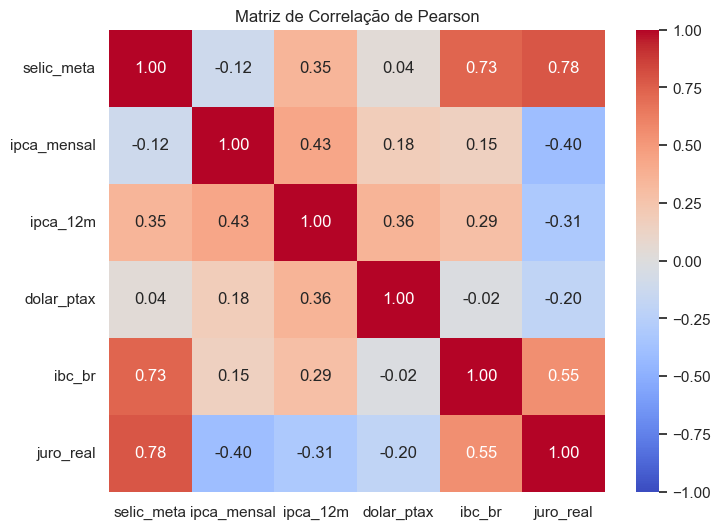

In [5]:
# Criando a matriz
colunas_economicas = ['selic_meta', 'ipca_mensal', 'ipca_12m', 'dolar_ptax', 'ibc_br', 'juro_real']
corr_matrix = df[colunas_economicas].corr()

# Transformando em ranking
pares = corr_matrix.unstack().sort_values(ascending=False)
# Removendo correlações de uma variável com ela mesma (1.0)
pares = pares[pares < 1.0]

print("--- TOP 5 Correlações Positivas ---")
display(pares.head(5))

print("\n--- TOP 5 Correlações Negativas ---")
display(pares.tail(5))

# Heatmap original
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Matriz de Correlação de Pearson')
plt.show()

Insight
A matriz comprova a interdependência das variáveis. A forte correlação positiva entre Selic e Juro Real (0,78) é esperada. Já a correlação negativa entre o Juro Real e o IPCA Mensal (-0,40) confirma que taxas reais mais altas são o principal instrumento para segurar a inflação no curto prazo.

⚠️ Limitações Metodológicas:

Correlação não implica Causalidade: A matriz de Pearson demonstra associação estatística, mas não prova que uma variável causou a outra.

Recorte Temporal (2019-2023): O período engloba a pandemia de COVID-19 e choques geopolíticos severos. Os padrões encontrados são específicos deste ciclo e não devem ser generalizados linearmente para outras décadas.